Files loaded successfully.

Calculated Actual Stabilized MAPE: 83.4849

Top 15 Predictions with Highest Stabilized Percentage Error:


,ID,Actual,Prediction,AbsoluteError,StabilizedPercentageError,Hasil_Panen_Ton_per_HA,Wilayah,Tahun,Jenis_Tanaman
1864,9864,-0.07,2.779327,2.849327,569.865450,2.970,'North West',2015,Coffee
118,8118,-0.52,1.951342,2.471342,475.258041,1.670,South,2006,Cotton
1701,9701,-0.41,1.827569,2.237569,447.513815,2.349,Northeast,2001,Fruits
582,8582,-0.62,2.090174,2.710174,437.124874,1.872,Northwest,2002,Cotton
544,8544,0.36,2.307546,1.947546,389.509177,2.790,Nouvelle-Aquitaine,2020,Corn
1461,9461,-0.71,1.929453,2.639453,371.753919,2.322,Northeast,2019,Cotton
164,8164,-0.23,1.599521,1.829521,365.904136,1.413,Nouvelle-Aquitaine,1998,Cotton
1142,9142,-0.75,1.854504,2.604504,347.267150,1.880,Ontario,2014,Barley
790,8790,-0.12,1.605056,1.725056,345.011192,2.043,Northwest,1994,Fruits
996,8996,0.01,1.717750,1.707750,341.549905,2.710,South,1999,Coffee


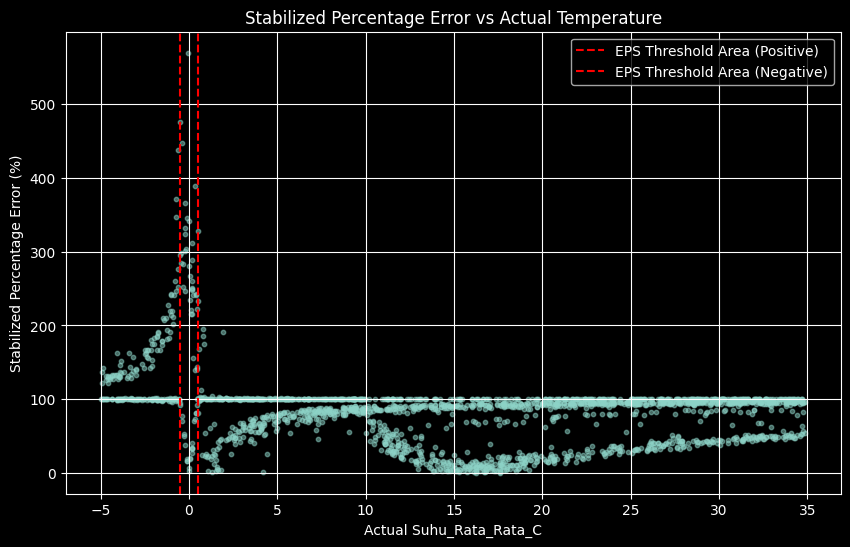

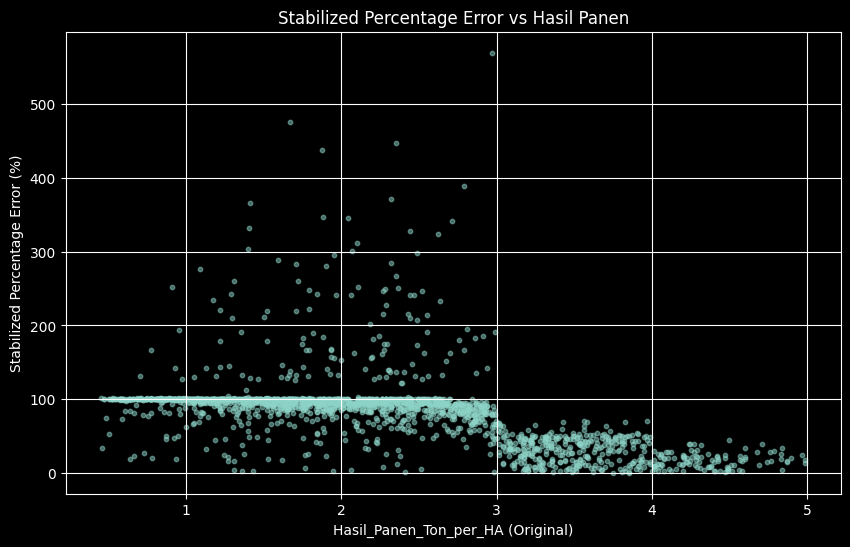

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the MAPE function again (assuming EPS=0.5)
EPS = 0.5
def mape_eps(y_true, y_pred, eps=EPS):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.maximum(np.abs(y_true), eps)
    denom = np.where(denom == 0, eps, denom) # Safety check
    return np.mean(np.abs(y_true - y_pred) / denom) * 100.0

# --- Load the data ---
try:
    submission_df = pd.read_csv(r"C:\Users\rapha\Downloads\submission_final_blend (1).csv") # Your model's predictions
    answer_key_df = pd.read_csv(r"C:\Users\rapha\Documents\VSCode\Kaggle\Intelecta Cup\kunci jawaban test.csv") # The actual answers
    test_features_df = pd.read_csv(r"C:\Users\rapha\Documents\VSCode\Kaggle\Intelecta Cup\Dataset\test.csv") # Original test features for context

    print("Files loaded successfully.")
except FileNotFoundError as e:
    print(f"Error loading files: {e}. Make sure both CSV files are uploaded.")
    raise

# --- Merge predictions and answers ---
# Rename columns for clarity before merging
submission_df = submission_df.rename(columns={'Suhu_Rata_Rata_C': 'Prediction'})
answer_key_df = answer_key_df.rename(columns={'Suhu_Rata_Rata_C': 'Actual'})

# Merge based on ID
comparison_df = pd.merge(answer_key_df, submission_df, on='ID', how='inner')

# Merge with original test features
comparison_df = pd.merge(comparison_df, test_features_df, on='ID', how='left')


# --- Calculate the Actual MAPE ---
actual_mape = mape_eps(comparison_df['Actual'], comparison_df['Prediction'])
print(f"\nCalculated Actual Stabilized MAPE: {actual_mape:.4f}")

# --- Analyze Errors ---
comparison_df['AbsoluteError'] = np.abs(comparison_df['Actual'] - comparison_df['Prediction'])
comparison_df['Denominator'] = np.maximum(np.abs(comparison_df['Actual']), EPS)
comparison_df['StabilizedPercentageError'] = (comparison_df['AbsoluteError'] / comparison_df['Denominator']) * 100

# Sort by the highest percentage error
comparison_df_sorted = comparison_df.sort_values(by='StabilizedPercentageError', ascending=False)

print("\nTop 15 Predictions with Highest Stabilized Percentage Error:")
display(comparison_df_sorted[['ID', 'Actual', 'Prediction', 'AbsoluteError', 'StabilizedPercentageError', 'Hasil_Panen_Ton_per_HA', 'Wilayah', 'Tahun', 'Jenis_Tanaman']].head(15))

# --- Plot Errors vs Actual Values ---
plt.figure(figsize=(10, 6))
plt.scatter(comparison_df['Actual'], comparison_df['StabilizedPercentageError'], alpha=0.5, s=10)
plt.xlabel("Actual Suhu_Rata_Rata_C")
plt.ylabel("Stabilized Percentage Error (%)")
plt.title("Stabilized Percentage Error vs Actual Temperature")
plt.grid(True)
# Highlight the EPS=0.5 threshold effect
plt.axvline(x=0.5, color='r', linestyle='--', label='EPS Threshold Area (Positive)')
plt.axvline(x=-0.5, color='r', linestyle='--', label='EPS Threshold Area (Negative)')
plt.legend()
plt.show()

# --- Plot Errors vs. Hasil Panen ---
# Use the original Hasil_Panen_Ton_per_HA for plotting if available
if 'Hasil_Panen_Ton_per_HA' in comparison_df.columns:
    plt.figure(figsize=(10, 6))
    plt.scatter(comparison_df['Hasil_Panen_Ton_per_HA'], comparison_df['StabilizedPercentageError'], alpha=0.5, s=10)
    plt.xlabel("Hasil_Panen_Ton_per_HA (Original)")
    plt.ylabel("Stabilized Percentage Error (%)")
    plt.title("Stabilized Percentage Error vs Hasil Panen")
    plt.grid(True)
    plt.show()
else:
    print("\nOriginal 'Hasil_Panen_Ton_per_HA' column not found in test_features_df for plotting.")